In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla

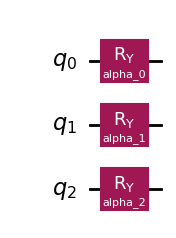

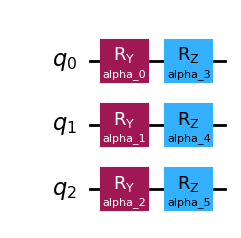

In [2]:
vqls_rz = oasis_dla.VQLS(qubits=3, ansatz_type=1)
vqls_ry = oasis_dla.VQLS(qubits=3, ansatz_type=0)

display(vqls_ry.ansatz.draw('mpl'))
display(vqls_rz.ansatz.draw('mpl'))

In [7]:
A_0 = np.eye(8) # 2^3
A_1 = 0.2 * np.kron(np.kron(oasis_dla.X, oasis_dla.Z), np.eye(2))
A_2 = 0.2 * np.kron(np.kron(oasis_dla.X, np.eye(2)), np.eye(2))
A = A_0 + A_1 + A_2

b = np.ones(8) / np.sqrt(8)

res = vqls_ry.solve(A, b)
q_soln = res.solution()
c_soln = np.linalg.solve(A, b).reshape(-1, 1)

Training time: 7.6417428999998265
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.5654144647214707e-14
       x: [ 1.571e+00  1.901e+00  1.571e+00]
     nit: 53
   maxcv: 0.0
    nfev: 51


In [8]:
print(f"Quantum Soln: \n{q_soln}")
print(f"Classical Soln: \n{c_soln}")

acc = vqls_ry.compute_accuracy(q_soln, c_soln)
print(f"Accuracy: {acc}")

Quantum Soln: 
[[0.25253811+0.j]
 [0.2525381 +0.j]
 [0.35355329+0.j]
 [0.35355326+0.j]
 [0.25253823+0.j]
 [0.25253821+0.j]
 [0.35355345+0.j]
 [0.35355342+0.j]]
Classical Soln: 
[[0.25253814+0.j]
 [0.25253814+0.j]
 [0.35355339+0.j]
 [0.35355339+0.j]
 [0.25253814+0.j]
 [0.25253814+0.j]
 [0.35355339+0.j]
 [0.35355339+0.j]]
Accuracy: 0.9999997793454767


In [9]:
res

Scaled Solution: [[0.25253811+0.j]
 [0.2525381 +0.j]
 [0.35355329+0.j]
 [0.35355326+0.j]
 [0.25253823+0.j]
 [0.25253821+0.j]
 [0.35355345+0.j]
 [0.35355342+0.j]]

In [11]:
prob_list = []
for i in range(0, 5):
    res = vqls_ry.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

Training time: 7.693154999999933
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0
       x: [ 1.571e+00  1.901e+00  1.571e+00]
     nit: 51
   maxcv: 0.0
    nfev: 49
Training time: 6.989003199999843
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.8984813721090177e-14
       x: [ 1.571e+00  1.901e+00  1.571e+00]
     nit: 49
   maxcv: 0.0
    nfev: 49
Training time: 7.811173399999916
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 8.326672684688674e-16
       x: [ 1.571e+00  1.901e+00  1.571e+00]
     nit: 51
   maxcv: 0.0
    nfev: 52
Training time: 6.719348300000092
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.6645352591003757e-15
       x: [ 1.571e+00  1.901e+00  1.571e+00]
     nit: 50
   maxcv: 0.0
    nfev: 47
Training time: 6.4220522

classical probabilities: [0.08445946 0.08445946 0.16554054 0.16554054 0.08445946 0.08445946
 0.16554054 0.16554054]


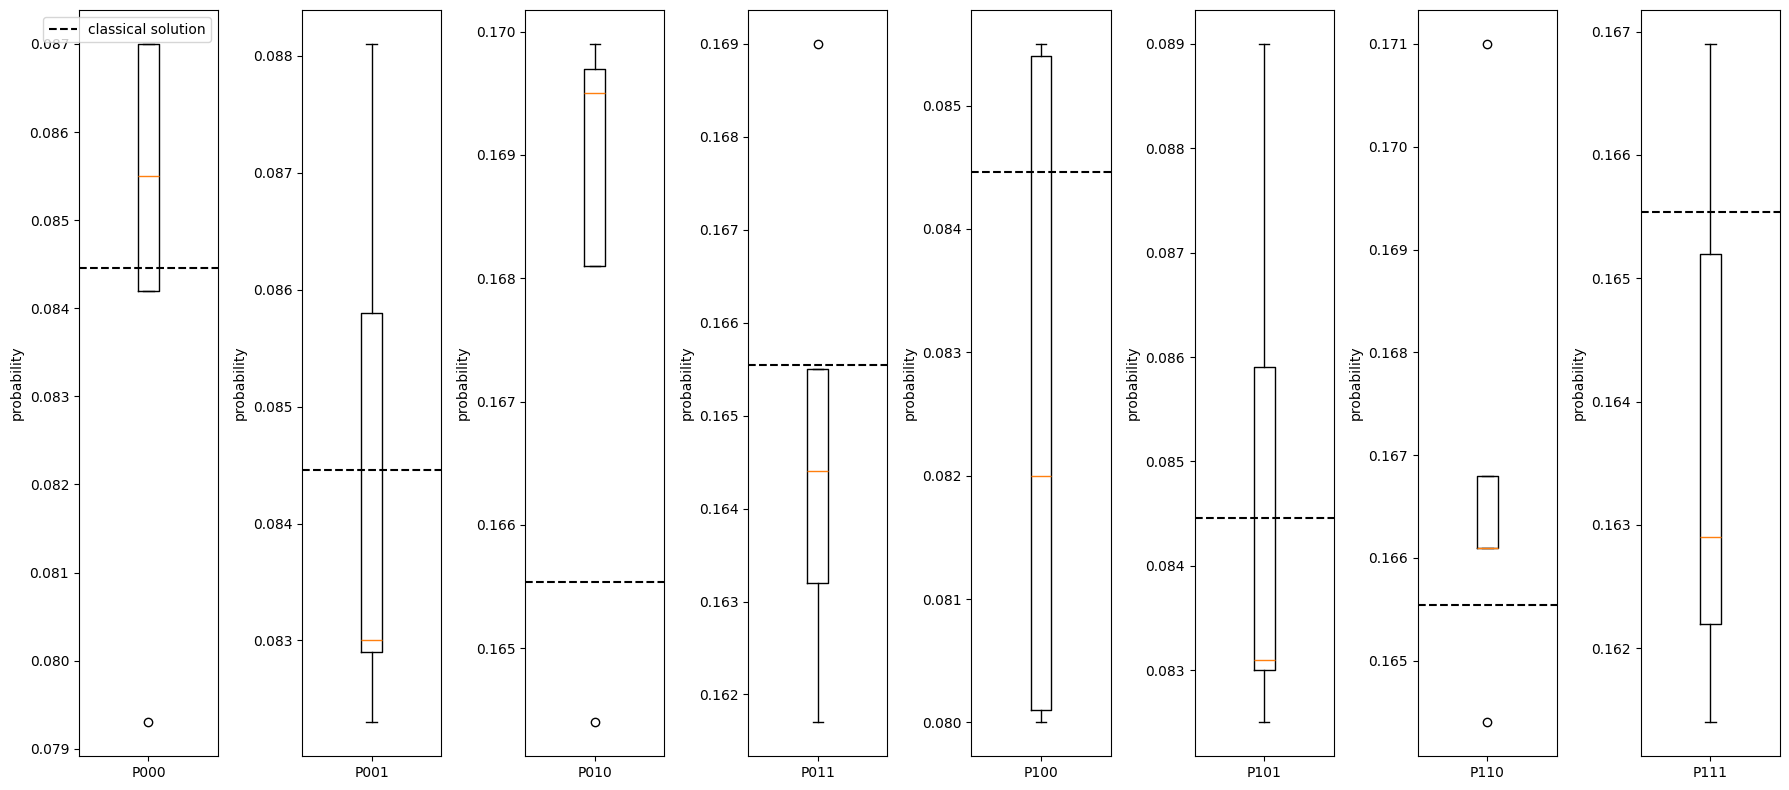

In [38]:
# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

p_quantum = [
    [probs.get(bitstr, 0) for probs in prob_list] for bitstr in [f"{x:03b}" for x in range(0, 8)]
]

p_quantum

fig, axes = plt.subplots(1, 8, figsize=(18, 8))
for ax, data, p_true, label in zip(axes, [*p_quantum], p_classical, [f"P{x:03b}" for x in range(0, 8)]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
plt.tight_layout()
plt.show()